In [34]:
import pandas as pd

In [35]:
data = {
 'Suhu': [15,15,15,15,
 70,70,70,70,
 125,125,125,125,
 15,15,15,15,
 70,70,70,70,
 125,125,125,125,
 15,15,15,15,
 70,70,70,70,
 125,125,125,125],
 
 'Umur': [130,155,74,180,
 34,40,80,75,
 20,70,82,58,
 150,188,159,126,
 136,122,106,115,
 25,70,58,45,
 138,110,168,160,
 174,120,150,139,
 96,104,82,60]
 }

In [36]:
df = pd.DataFrame(data)
print(df.head())

   Suhu  Umur
0    15   130
1    15   155
2    15    74
3    15   180
4    70    34


In [37]:
stats_manual = df.groupby('Suhu')['Umur'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])
print("=== Statistik Deskriptif Umur menurut Suhu ===")
print(stats_manual.to_string())

=== Statistik Deskriptif Umur menurut Suhu ===
      count        mean        std  min  median  max
Suhu                                                
15       12  144.833333  31.694087   74   152.5  188
70       12  107.583333  42.883475   34   117.5  174
125      12   64.166667  25.672176   20    65.0  104


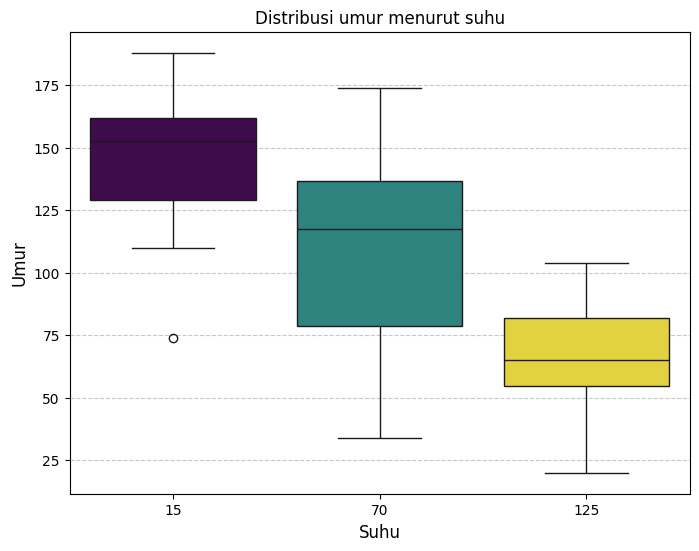

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(x='Suhu', y='Umur', data=df, palette='viridis', hue='Suhu', legend=False)
plt.title('Distribusi umur menurut suhu')
plt.xlabel('Suhu', fontsize=12)
plt.ylabel('Umur', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [39]:
from statsmodels.formula.api import ols 
from statsmodels.stats.anova import anova_lm 

# Mengubah model utoma agar hanya menganallsis faktor Suhu 
model = ols('Umur ~ C(Suhu)', data=df).fit() 
anova_table = anova_lm(model, typ=2)

In [40]:
print(anova_table)

                sum_sq    df          F   PR(>F)
C(Suhu)   39118.722222   2.0  16.752874  0.00001
Residual  38528.250000  33.0        NaN      NaN


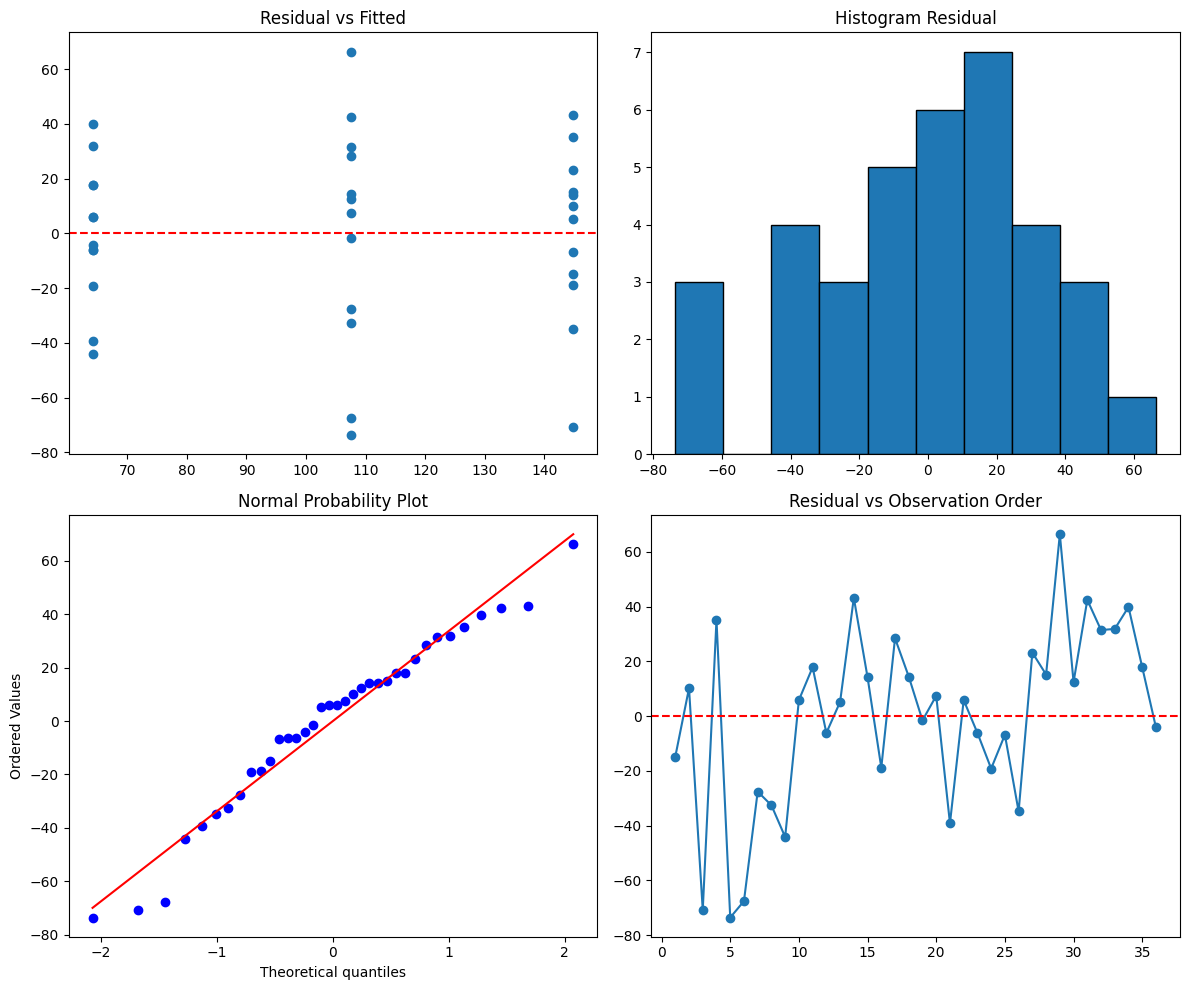

In [41]:
import matplotlib.pyplot as plt
import scipy.stats as stats

fig, ax = plt.subplots(2, 2, figsize=(12,10))

# 1. Residual vs Fitted
ax[0,0].scatter(model.fittedvalues, model.resid)
ax[0,0].axhline(0, color='red', linestyle='--')
ax[0,0].set_title('Residual vs Fitted')

# 2. Histogram Residual
ax[0,1].hist(model.resid, bins=10, edgecolor='black')
ax[0,1].set_title('Histogram Residual')

# 3. QQ Plot
stats.probplot(model.resid, dist='norm', plot=ax[1,0])
ax[1,0].set_title('Normal Probability Plot')

# 4. Residual vs Run Order
ax[1,1].plot(range(1, len(model.resid)+1),
             model.resid,
             marker='o')
ax[1,1].axhline(0, color='red', linestyle='--')
ax[1,1].set_title('Residual vs Observation Order')

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd

influence = model.get_influence()
studentized = influence.resid_studentized_internal

# Memasukkan hasil studentized residuals ke DataFrame baru untuk dianalisis
df_diag = df.copy()
df_diag['Studentized_Residual'] = studentized

# Menampilkan data yang memiliki residual cukup besar (|residual| > 3) tanpa kolom Material
outliers = df_diag[df_diag['Studentized_Residual'].abs() > 3][['Suhu', 'Umur', 'Studentized_Residual']]

print("=== Analisis Studentized Residuals (Model Faktor Suhu) ===")
print(f"Rata-rata Studentized Residual: {studentized.mean():.4f}")
print(f"Standar Deviasi               : {studentized.std():.4f}")
print(f"Nilai Maksimum                : {studentized.max():.4f}")
print(f"Nilai Minimum                 : {studentized.min():.4f}")

print("\n=== Data Terindikasi Outliers (|Residual| > 3) ===")
if len(outliers) > 0:
    print(outliers.to_string())
else:
    print("Tidak ditemukan data pencilan (outliers).")

=== Analisis Studentized Residuals (Model Faktor Suhu) ===
Rata-rata Studentized Residual: 0.0000
Standar Deviasi               : 1.0000
Nilai Maksimum                : 2.0302
Nilai Minimum                 : -2.2493

=== Data Terindikasi Outliers (|Residual| > 3) ===
Tidak ditemukan data pencilan (outliers).


In [43]:
from scipy.stats import shapiro
residual = model.resid
stat, p = shapiro(residual)
print("Statistik =", stat)
print("p-value =", p)

if p > .05:
    print('Residual berdistribusi normal')
else:
    print('Residual tidak normal')

Statistik = 0.9644940322329493
p-value = 0.2945644550274218
Residual berdistribusi normal


In [44]:
from scipy.stats import kstest, zscore
import numpy as np

# Menggunakan residual yang diperoleh dari model
residual = model.resid

# Standardisasi residual (Z-score)
residual_z = zscore(residual)

# Menjalankan Uji Kolmogorov-Smirnov terhadap distribusi normal standar
stat, p = kstest(residual_z, 'norm')

print("=== Hasil Uji Kolmogorov-Smirnov ===")
print("Statistik =", stat)
print("p-value =", p)

if p > 0.05:
    print("Residual berdistribusi normal (Gagal menolak H0)")
else:
    print("Residual tidak berdistribusi normal (Menolak H0)")

=== Hasil Uji Kolmogorov-Smirnov ===
Statistik = 0.11830063915495492
p-value = 0.6515943412224041
Residual berdistribusi normal (Gagal menolak H0)


In [45]:
from scipy.stats import levene

groups = [
    group["Umur"].values
    for _, group in df.groupby(["Suhu"])
]

stat, p = levene(*groups)

print("Statistik =", stat)
print("p-value =", p)

if p > 0.05:
    print("Variansi homogen")
else:
    print("Variansi tidak homogen")

Statistik = 1.0445272045506726
p-value = 0.36320141987586796
Variansi homogen


In [ ]:
from scipy.stats import bartlett

groups = [
    group["Umur"].values
    for _, group in df.groupby(["Suhu"])
]

stat, p = bartlett(*groups)

print("Statistik =", stat)
print("p-value =", p)

if p > 0.05:
    print("Variansi homogen")
else:
    print("Variansi tidak homogen")